# ECCOFS on AWS, and which model to use when

The [East Coast Community Ocean Forecast System (ECCOFS)](https://registry.opendata.aws/noaa-nos-eccofs/) is a ROMS data-assimilative analysis and forecast system on AWS (bucket `noaa-nos-eccofs-pds`, public). Its outputs are described in the [ECCOFS wiki](https://github.com/myroms/roms_eccofs/wiki/Analysis-and-forecast-outputs); the project describes them as experimental and pre-operational. Unlike Doppio, it was only available as NetCDF when this was written: no Zarr, JSON or reference files.

This notebook

1. explains how the files are organized and how to get **one value per day** despite overlapping forecast cycles,
2. extracts a month of profiles at the OOI NOPM mooring, and
3. recommends which ECCOFS collection, and which model, to use for OOI comparisons.

See `doppio_aws_access.ipynb` for the access methods in more detail.

In [7]:
import time

import h5py
import matplotlib.pyplot as plt
import numpy as np
import s3fs

# OOI Pioneer Northern Offshore Profiler Mooring (NOPM)
nopm_lat, nopm_lon = 36.17983, -74.82667

s3 = s3fs.S3FileSystem(anon=True)

def open_eccofs(date, n=1):
    """Open avg file `n` (1-8) of cycle 'YYYYMMDD' with h5py, reading lazily from S3."""
    f = s3.open(
        f"noaa-nos-eccofs-pds/avg/eccofs_avg_{date}_{n:04d}.nc",
        mode="rb", cache_type="readahead", block_size=5 * 2**20,
    )
    return h5py.File(f, "r")

def model_time(h):
    """The time of the single time step in an avg file."""
    return np.datetime64("2011-01-01T00:00:00") + np.timedelta64(int(h["ocean_time"][0]), "s")

## 1. The output collections

| Collection | Contents | Time resolution | One file holds |
|---|---|---|---|
| `avg/` | Ocean state, fluxes and mixing, plus derived fields (vorticity, ocean heat content, mixed-layer depth), all 50 levels | Daily **means**, centered on 12:00 UTC | 1 day |
| `his/` | Ocean state, fluxes, stresses and mixing, all 50 levels | Once-daily **snapshot** at 00:00 UTC | 1 day |
| `qck/` | 2-D fields only: sea level, surface temperature, salinity and velocity, plus temperature, salinity and velocity at 2, 50 and 100 m | 3-hourly snapshots | a whole cycle |
| `sta/` | Time series at a fixed list of observing sites | Hourly | a whole cycle |
| `frc/`, `riv/`, `obs/` | Model inputs: meteorological forcing, river inflow, assimilated observations | | |

What we checked directly:
- `avg` files are NetCDF4/HDF5 (about 7.6 GB each), so `h5py` / `h5netcdf` can read them lazily from S3. A full 50-level profile at one point is a single 4.8 MB chunk, not 7.6 GB.
- `his` files (about 4.6 GB) are *classic* NetCDF (they start with `CDF`), which `h5py` cannot open.
- `qck` files are 7.7-12 GB per cycle (a separate `_fwd` file also exists). `sta` files are about 15 MB. Neither has been opened here.

`sta` covers only a fixed list of sites, so it cannot serve an arbitrary mooring location and is not used here.

## 2. One value per day: analysis vs forecast files

ECCOFS runs a new cycle every day. Per the wiki, the date in a file name is the **start of the 3-day assimilation window**, and the suffix tells you what the file holds:

| Suffix | Contents | Valid day (cycle `D`) |
|---|---|---|
| `0001`-`0003` | **Analysis** (assimilates observations) | `D`, `D+1`, `D+2` |
| `0004`-`0008` | **Forecast** from the end of the analysis | `D+3` to `D+7` |

Each `avg` file is one day, so it has a single time step. But because cycles overlap, the same day appears in several files (for example as analysis day 1 in one cycle and analysis day 2 in the previous one, and also in older forecasts). To get **exactly one analysis value per day**, take the same analysis suffix from every cycle. The docs do not say which of `0001`-`0003` is best, so this notebook uses `0001`, the first day of each window. The cells below check this against the file times.

In [8]:
# The 8 files of one cycle: read just the tiny time coordinate of each
for n in range(1, 9):
    kind = "analysis" if n <= 3 else "forecast"
    print(n, kind, model_time(open_eccofs("20260608", n)))

# The same valid day shows up in two different cycles:
a = model_time(open_eccofs("20260608", 2))
b = model_time(open_eccofs("20260609", 1))
print("\n20260608 file 0002 =", a, "| 20260609 file 0001 =", b, "| same day:", a == b)

1 analysis 2026-06-08T12:00:00
2 analysis 2026-06-09T12:00:00
3 analysis 2026-06-10T12:00:00
4 forecast 2026-06-11T12:00:00
5 forecast 2026-06-12T12:00:00
6 forecast 2026-06-13T12:00:00
7 forecast 2026-06-14T12:00:00
8 forecast 2026-06-15T12:00:00

20260608 file 0002 = 2026-06-09T12:00:00 | 20260609 file 0001 = 2026-06-09T12:00:00 | same day: True


In [9]:
# Metadata only, no data is read: shapes and chunking of the main variables
h = open_eccofs("20260608")
for name in ("temp", "lon_rho", "lat_rho", "mask_rho", "h"):
    d = h[name]
    print(f"{name:8} shape={d.shape} chunks={d.chunks} ~{d.size * d.dtype.itemsize / 1e6:.0f} MB")

# Nearest model cell to NOPM (reads the full lon/lat grids once, ~10 MB each)
t0 = time.time()
lon, lat = h["lon_rho"][:], h["lat_rho"][:]
dist = (lat - nopm_lat) ** 2 + ((lon - nopm_lon) * np.cos(np.deg2rad(nopm_lat))) ** 2
j_e, i_e = np.unravel_index(np.argmin(dist), dist.shape)
print(f"\nNearest cell: eta_rho={j_e}, xi_rho={i_e}, depth={h['h'][j_e, i_e]:.0f} m, land mask={h['mask_rho'][j_e, i_e]:.0f} ({time.time() - t0:.0f}s)")

temp     shape=(1, 50, 1443, 1667) chunks=(1, 50, 145, 167) ~481 MB
lon_rho  shape=(1443, 1667) chunks=None ~10 MB
lat_rho  shape=(1443, 1667) chunks=None ~10 MB
mask_rho shape=(1443, 1667) chunks=(481, 556) ~10 MB
h        shape=(1443, 1667) chunks=(481, 556) ~10 MB

Nearest cell: eta_rho=1158, xi_rho=931, depth=161 m, land mask=1 (2s)


## 3. A month of profiles at NOPM

One profile per day for October 2026, from analysis file `0001` of each cycle. Each profile comes from a different 7.6 GB file but reads only one 4.8 MB chunk, which took about 2 s per file in one run, so expect about a minute.

31 profiles in 101s


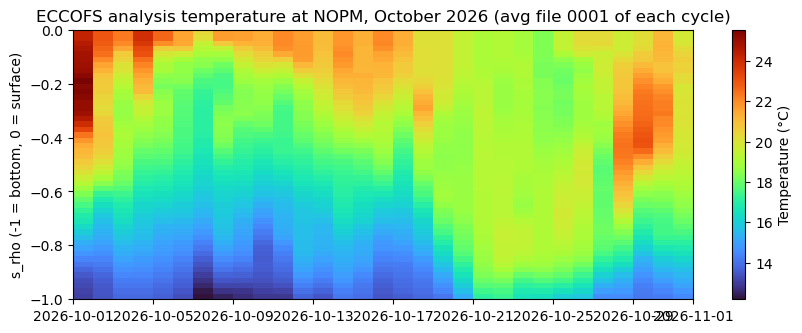

In [10]:
dates = [str(d).replace("-", "") for d in np.arange("2026-10-01", "2026-11-01", dtype="datetime64[D]")]

times, profiles = [], []
t_all = time.time()
for date in dates:
    hf = open_eccofs(date, 1)
    times.append(model_time(hf))
    profiles.append(hf["temp"][0, :, j_e, i_e])
print(f"{len(dates)} profiles in {time.time() - t_all:.0f}s")
assert len(set(times)) == len(times), "duplicate valid days"

s_rho = h["s_rho"][:]
fig, ax = plt.subplots(figsize=(10, 3.5))
pc = ax.pcolormesh(times, s_rho, np.array(profiles).T, shading="nearest", cmap="turbo")
ax.set_ylabel("s_rho (-1 = bottom, 0 = surface)")
ax.set_title("ECCOFS analysis temperature at NOPM, October 2026 (avg file 0001 of each cycle)")
fig.colorbar(pc, label="Temperature (°C)")
plt.show()

## 4. Which ECCOFS collection?

For comparing with OOI profiler data:

- **`avg` (recommended):** full-depth daily means, one analysis file per day, readable lazily (this notebook). Average the OOI profiles over the same UTC day before comparing, since a daily mean is centered on 12:00 UTC.
- **`his`:** a once-daily *snapshot* at 00:00 UTC, not an hourly product, and stored in a classic NetCDF format that `h5py` cannot open. Use it only if you specifically need instantaneous snapshots; `avg` is the better starting point.
- **`qck`:** 3-hourly, but only surface fields and temperature, salinity and velocity at 2, 50 and 100 m. It could suit surface or fixed-depth comparisons, not full profiles. Each file holds a whole cycle (analysis and forecast days) and is 7.7-12 GB, so you would need to select the analysis times. Not examined yet.
- **`sta`:** hourly, but only at a fixed list of sites. Not suitable for arbitrary locations.

ECCOFS has **no hourly, full-depth gridded product**. For hourly profiles, use Doppio `his` (see below).

## 5. Which model for which period?

The OOI NOPM profiler data begin on 2024-04-17 (from the OOI ERDDAP dataset metadata). Which model can be compared depends on the period:

| Period | Model source | Time resolution | Notes |
|---|---|---|---|
| Apr - Dec 2024 | Doppio reanalysis on AWS | `avg` daily, `his` hourly | Zarr reference files exist for `avg`, `his` and `flx`. The archive ends 2024-12-30 (`his` 2024-12-31 00:00). |
| Jan 2025 - early Jun 2026 | Rutgers THREDDS `roms/doppio/2017_da/his/History_Best` | hourly | Starts 2017-11-02 and runs into 2026 (check `ds.time.max()`). It supports OPeNDAP subsetting, but large requests are limited (see `roms_benchmarks.ipynb`). Neither AWS archive covers this gap. |
| Jun 2026 onward | ECCOFS `avg` on AWS | daily means | Pre-operational. Doppio on THREDDS gives hourly data for the same period. |

Points to keep in mind:
- **Hourly profiles from AWS Doppio are expensive:** its `his` chunks span the whole grid for one level, so a month of hourly profiles at one point reads about 1,200 chunks (see `doppio_aws_benchmarks.ipynb`).
- **Different products:** the AWS Doppio reanalysis and the THREDDS `2017_da` run are not necessarily the same model run. Compare their values before mixing them in one analysis.
- **Not yet checked:** the exact end date of the THREDDS dataset, and the contents of the ECCOFS `qck` files.